# Sanity check

The point is to show that north ecliptical pole never rises above horizon.

In [1]:
import lusee
import numpy as np
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord

/home/anze/venv/luseepy/lib/python3.11/site-packages/astropy/config/paths.py:55: AstropyUserWarning: XDG_CONFIG_HOME is set to '/home/anze/.config', but the default location, /home/anze/.astropy/config, already exists, and takes precedence. This environment variable will be ignored.
  return set_temp_config._get_dir_path(rootname)

: XDG_CONFIG_HOME is set to '/home/anze/.config', but the default location, /home/anze/.astropy/config, already exists, and takes precedence. This environment variable will be ignored. [astropy.config.paths]
/home/anze/venv/luseepy/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# north 
ra_deg, dec_deg  = 18/24*360, 66.5
# Create a SkyCoord object with the RA and Dec coordinates
coords = SkyCoord(ra=ra_deg, dec=dec_deg, unit='deg', frame='icrs')

# Convert the coordinates to Galactic coordinates
galactic_coords = coords.galactic

# Access the Galactic longitude and latitude
galactic_lon = float(galactic_coords.l.deg)
galactic_lat = float(galactic_coords.b.deg)

# Print the Galactic coordinates
print("Galactic Longitude:", galactic_lon)
print("Galactic Latitude:", galactic_lat)

Galactic Longitude: 96.314009428501
Galactic Latitude: 29.81144601404902


In [3]:
deltaT=3600*10 #In seconds
obs = lusee.Observation('2026-01-11 12:00:00 to 2026-02-11 00:00:00', deltaT_sec=deltaT)
alt, az = obs.get_track_ra_dec(ra_deg, dec_deg)
alt2, az2 = obs.get_track_l_b(galactic_lon, galactic_lat)


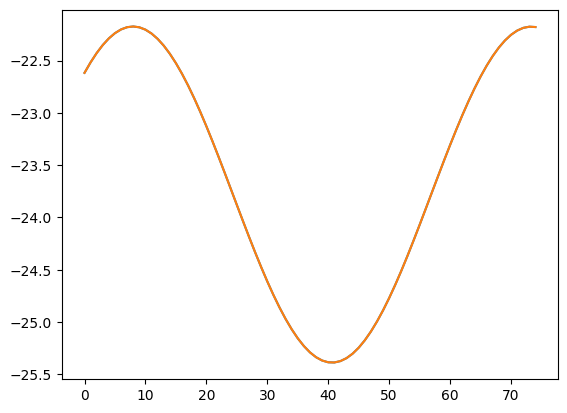

In [4]:

plt.plot(alt*180/np.pi)
plt.plot(alt2*180/np.pi)

In [17]:
from lunar_altaz import lunar_altaz_from_mcmf
alt3, az3 = np.array([lunar_altaz_from_mcmf(obs.lun_long, obs.lun_lat, time.mjd, ra_deg/180*np.pi, dec_deg/180*np.pi) for time in obs.times]).T

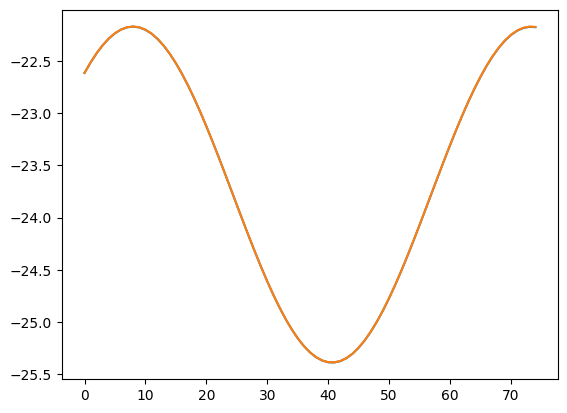

In [19]:

plt.plot(alt*180/np.pi)
plt.plot(alt3*180/np.pi)



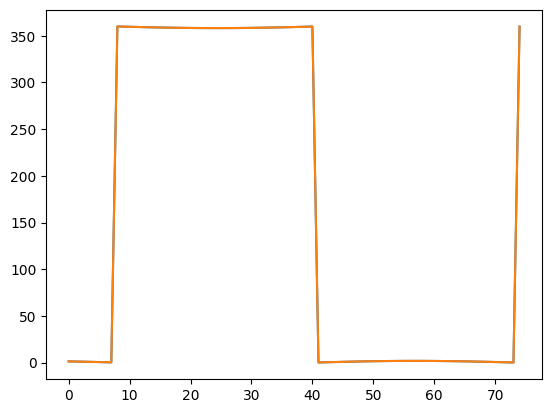

In [20]:

plt.plot(az*180/np.pi)
plt.plot(az3*180/np.pi)
